# TP · Де поставити вежі, щоб побачити найбільше майбутніх пожеж?

**Тип:** сценарний аналіз. **Навіщо:** Де розмістити кілька точок огляду, щоб у поле зору з урахуванням рельєфу потрапляла найбільша частка майбутніх пожеж.

Цей ноутбук повторює блок сторінки досліджень `web/science/#tp` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('TP'))

TP · Де ставити вежі: чи бачили б вони майбутні пожежі.

Задача      обрати 3 місця для веж (огляд 360°, щогла 15 м, 10 км), щоб побачити якнайбільше пожеж.
Дані        гекси парку H3 res 9, рельєф SRTM, точки NASA FIRMS 2021–2025, зведені в пожежі правилом FM (2 км, 5 діб).
Протокол    прогресивний: для кожного року Y вежі ставимо лише за тим, що відомо до Y, і перевіряємо на пожежах року Y.
            Валідація 2022, тест 2023, 2024, 2025 разом і окремо. Вибір лише на валідації. Той самий протокол у CP і LG.
            Різниця з випадковими місцями: парний бутстреп за пожежами тесту.
Метрики     first: частка пожеж, перша точка яких у полі зору, головна. any: хоч одна точка.
            burn: частка згорілих гексів у полі зору. Інтервал: бутстреп за пожежами.
Підходи
  random        випадкові 3 місця, 1000 спроб
  peaks         3 найвищі точки на відстані
  spread        рівномірно по парку: k-means, найвища точка кластера
  greedy_*      жадібне покриття з вагою: flat ліс, elev ви

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,first,first_lo,first_hi,any,burn,diff,diff_lo,diff_hi,champion
0,random,0.150,0.100,0.204,0.233,0.273,0.000,0.000,0.000,False
1,peaks,0.000,0.000,0.000,0.077,0.393,-0.150,-0.204,-0.102,False
2,spread,0.000,0.000,0.000,0.077,0.582,-0.150,-0.204,-0.100,False
5,greedy_flat,0.385,0.154,0.615,0.385,0.715,0.234,0.021,0.454,True
8,greedy_elev,0.385,0.154,0.615,0.385,0.715,0.234,0.029,0.448,False
11,greedy_firms,0.385,0.154,0.615,0.385,0.715,0.234,0.024,0.458,False
14,greedy_loss,0.385,0.154,0.615,0.385,0.715,0.234,0.033,0.446,False
17,greedy_suscept,0.385,0.154,0.692,0.385,0.715,0.234,0.033,0.468,False
20,greedy_risk,0.385,0.154,0.692,0.385,0.715,0.234,0.029,0.477,False
21,random,0.885,0.850,0.920,0.898,0.939,0.000,0.000,0.000,False


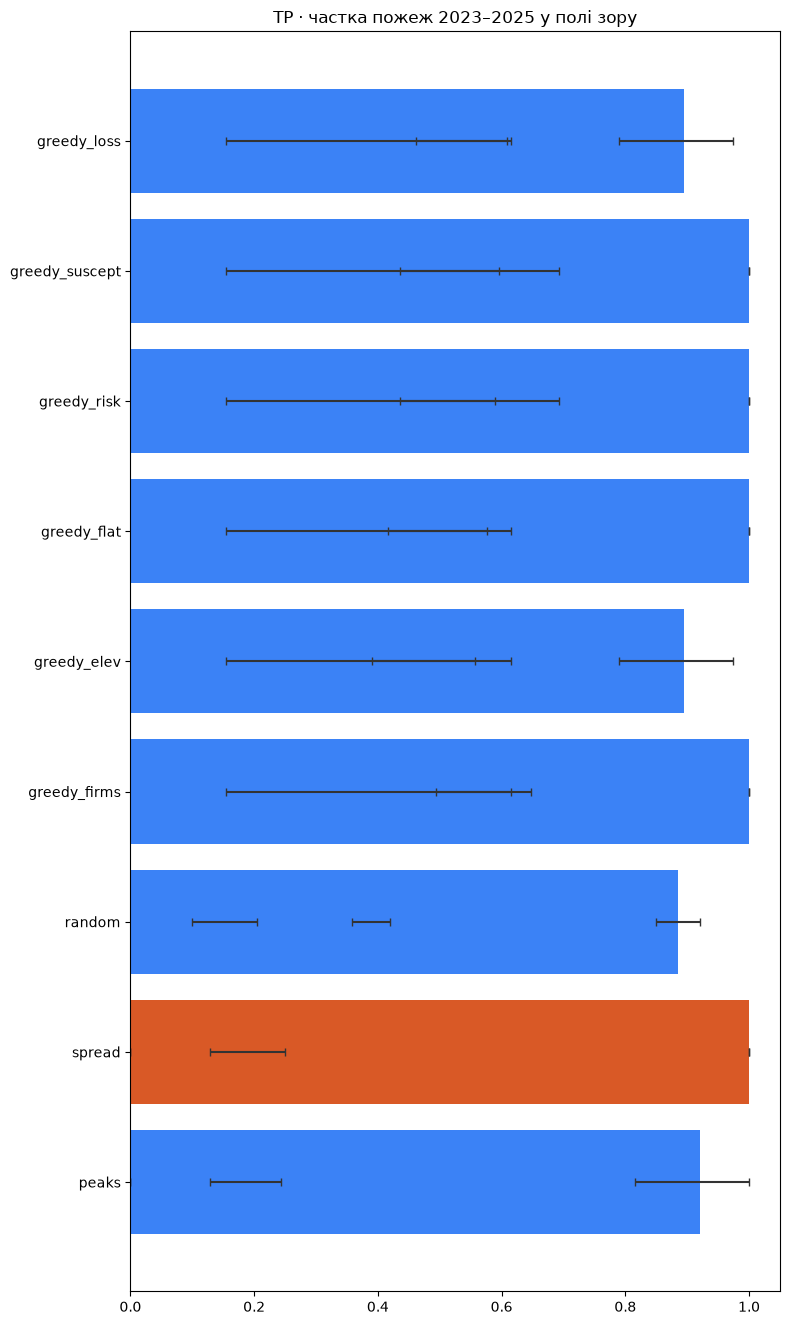

In [3]:
table, fig = report.show('TP')
table

## По роках

Прогресивний протокол: кожен рік бачить лише дані до нього.

In [4]:
report.by_year('TP')

approach,greedy_elev,greedy_firms,greedy_flat,greedy_loss,greedy_risk,greedy_suscept,peaks,random,spread
year,,,,,,,,,
2022.0,0.553,0.602,0.604,0.588,NaN,0.605,0.465,0.521,0.568
2023.0,0.519,0.569,0.540,0.530,0.580,0.543,0.401,0.484,0.401
2024.0,0.422,0.454,0.454,0.462,0.454,0.454,0.367,0.424,0.415
2025.0,0.585,0.652,0.639,0.611,0.697,0.641,0.341,0.490,0.372
